# O público de cinema voltou depois da pandemia?

É essa a pergunta que guia o notebook. Quero saber se o público dos cinemas brasileiros voltou ao que era em 2019 e, se não voltou, o que explica a diferença.

Para chegar lá, quebrei em perguntas menores:
1. A recuperação depende de poucos sucessos?
2. Quanto do público vai para filmes brasileiros?
3. Faltam salas e sessões ou falta gente nas sessões?
4. Em que lugares o público não voltou?
5. Quais empresas ganharam e quais perderam espaço?
6. Como é a vida de um filme em cartaz?
7. Quando o público vai ao cinema?
8. Dublado ou legendado?

Os dados são a bilheteria diária da ANCINE, de 2014 a setembro de 2026, já limpos (`dados/bilheteria_limpa.csv.gz`; a limpeza está em `dados/limpeza_bilheteria_unificada.ipynb`).

Um cuidado antes de começar: a ANCINE recebe os números de duas fontes, e as duas descrevem as mesmas sessões. Por isso nunca somo uma com a outra.
- Distribuidoras: uma linha por dia, sala e filme. É a série completa desde 2014, e é a que uso na maior parte das contas.
- Exibidoras: uma linha por sessão. Tem horário e tipo de cópia (dublada ou legendada), mas só cobre o país inteiro a partir de 2017.

Como 2026 ainda vai só até setembro, quando comparo com 2026 uso os mesmos meses (janeiro a setembro) nos outros anos. As decisões de tratamento estão em `contexto.md`.

In [1]:
import calendar
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", None)

Para os gráficos terem a cara do dashboard, uso as cores do design system Pastel Noturno, no modo escuro (`DESIGN_SYSTEM.md`): lavanda para a série principal, pêssego para os anos que quero destacar e cinza para as linhas de referência. O dashboard usa a fonte Geist. Aqui fica a Inter, que é a alternativa prevista no design system e já está instalada no computador.

In [2]:
# cores do dashboard (DESIGN_SYSTEM.md, modo escuro)
FUNDO = "#171717"      # mesma cor dos cartões do dashboard
TEXTO = "#FFFFFF"
TEXTO_SEC = "#A3A3A3"
LAVANDA = "#A47EE2"    # série principal
PESSEGO = "#C3864E"    # anos em destaque / abaixo da média
CINZA = "#8A8A8A"      # linha de referência

In [3]:
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110, "font.family": "Inter", "font.size": 11,
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "axes.edgecolor": "#333333",
    "text.color": TEXTO, "xtick.color": TEXTO_SEC, "ytick.color": TEXTO_SEC,
    "axes.titlecolor": TEXTO, "axes.titlesize": 14, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
})

In [4]:
# números no padrão brasileiro: ponto no milhar e vírgula no decimal
def br(valor, casas=0):
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

def mi(valor):
    return br(valor / 1_000_000, 1) + " mi"

def pct(valor, casas=1):
    return br(valor * 100, casas) + "%"

In [5]:
# gráfico de colunas por ano; os anos em "destaques" ficam em pêssego
def grafico_anos(serie, titulo, formato, destaques=[2019]):
    cores = [PESSEGO if ano in destaques else LAVANDA for ano in serie.index]
    fig, ax = plt.subplots()
    barras = ax.bar(serie.index.astype(str), serie.values, color=cores)
    ax.bar_label(barras, labels=[formato(v) for v in serie.values], fontsize=9, padding=2, color=TEXTO_SEC)
    ax.set_title(titulo)
    ax.set_yticks([])
    plt.show()

In [6]:
def grafico_lista(serie, titulo, formato, referencia=None):
    serie = serie.sort_values()   # da menor para a maior; abaixo da referência fica em pêssego
    cores = [PESSEGO if referencia is not None and v < referencia else LAVANDA for v in serie.values]
    fig, ax = plt.subplots(figsize=(10, max(4, 0.32 * len(serie))))
    barras = ax.barh(serie.index, serie.values, color=cores)
    ax.bar_label(barras, labels=[formato(v) for v in serie.values], fontsize=9, padding=3, color=TEXTO_SEC)
    if referencia is not None:
        ax.axvline(referencia, color=CINZA, linestyle="--", linewidth=1)
    ax.set(title=titulo, xticks=[])
    plt.show()

O CSV limpo tem uns 60 milhões de linhas, então não dá para abrir direto no pandas. Na primeira vez, converto o arquivo para Parquet em `saidas/` e faço as contas pesadas em SQL com o DuckDB, que lê esse formato em segundos. O resultado de cada consulta já volta como tabela do pandas.

In [7]:
con = duckdb.connect()
con.execute("SET memory_limit='6GB'")
con.execute("SET temp_directory='saidas/.duckdb_tmp'")
con.execute("SET preserve_insertion_order=false")
con.execute("SET enable_progress_bar=false")


def consulta(sql):
    return con.execute(sql).df()

In [8]:
# só converte na primeira vez; depois o parquet já existe
if not Path("saidas/bilheteria_limpa.parquet").exists():
    con.execute("""
        COPY (SELECT * FROM read_csv('dados/bilheteria_limpa.csv.gz', header=true,
              types={'data_exibicao': 'DATE', 'sessao': 'TIMESTAMP', 'data_hora_envio_protocolo': 'TIMESTAMP', 'publico': 'INTEGER'}))
        TO 'saidas/bilheteria_limpa.parquet' (FORMAT parquet, COMPRESSION zstd)
    """)

con.execute("CREATE OR REPLACE VIEW t AS SELECT * FROM 'saidas/bilheteria_limpa.parquet'");

## Os dados foram lidos certo?

Antes de qualquer conta, confiro quantas linhas, quanto público e que período cada fonte tem, para comparar com a reconciliação feita na limpeza.

In [9]:
leitura = consulta("""
    SELECT fonte, count(*) AS n_linhas, sum(publico) AS publico,
           min(data_exibicao) AS primeiro_dia, max(data_exibicao) AS ultimo_dia
    FROM t
    GROUP BY fonte
    ORDER BY fonte
""")
leitura.style.format({"n_linhas": br, "publico": br})

,fonte,n_linhas,publico,primeiro_dia,ultimo_dia
0,distribuidor,21.655.622,1.695.424.906,2014-01-01 00:00:00,2026-09-30 00:00:00
1,exibidora,38.401.117,1.232.956.821,2014-06-01 00:00:00,2026-10-18 00:00:00


Bateu certinho com a reconciliação da limpeza: 21.655.622 linhas e 1.695.424.906 espectadores na fonte das distribuidoras, e 38.401.117 linhas e 1.232.956.821 espectadores na das exibidoras. As datas também estão dentro do esperado. Dei uma olhada em algumas linhas para ver se os acentos e os horários vieram certos:

In [10]:
consulta("""
    SELECT data_exibicao, sessao, coalesce(titulo_brasil, titulo_original) AS filme,
           nome_sala, uf_sala_complexo, publico
    FROM t
    WHERE fonte = 'exibidora' AND data_exibicao = DATE '2025-07-19'
    LIMIT 3
""")

,data_exibicao,sessao,filme,nome_sala,uf_sala_complexo,publico
0,2025-07-19,2025-07-19 08:00:00,CORRIDA MALUCA,GRUPOCINE AMARGOSA 02,BA,0
1,2025-07-19,2025-07-19 09:00:00,UM FILME MINECRAFT,CINEMARK ITABUNA 04,BA,50
2,2025-07-19,2025-07-19 10:00:00,ELIO,CINE 14 BIS 02,MG,5


## Duas bases, para não contar o mesmo público duas vezes

Monto duas tabelas de trabalho:
- `d`, das distribuidoras, com uma linha por exibição (dia + sala + filme). Quando duas distribuidoras dividem um filme, a mesma exibição aparece duas vezes na origem. Aqui ela conta uma vez só, com o maior público informado. É a mesma regra do dashboard.
- `e`, das exibidoras, com uma linha por sessão, só de 2017 em diante.

A coluna `tipo` é a primeira letra do código da obra (CPB/ROE): B é filme brasileiro, E é estrangeiro e G são eventos, mostras e shows.

In [11]:
con.execute("""
    CREATE OR REPLACE TABLE d AS
    SELECT data_exibicao AS dia, registro_sala, nome_sala, cpb_roe, left(cpb_roe, 1) AS tipo,
           any_value(uf_sala_complexo) AS uf, any_value(municipio_sala_complexo) AS municipio,
           max(publico) AS publico   -- co-distribuição: fica o maior público informado
    FROM t
    WHERE fonte = 'distribuidor'
    GROUP BY data_exibicao, registro_sala, nome_sala, cpb_roe
""")
consulta("SELECT count(*) AS n_exibicoes, sum(publico) AS publico FROM d")

,n_exibicoes,publico
0,21627502,1.693404e+09


In [12]:
con.execute("""
    CREATE OR REPLACE TABLE e AS
    SELECT data_exibicao AS dia, sessao, registro_sala, cpb_roe, left(cpb_roe, 1) AS tipo,
           audio, uf_sala_complexo AS uf, registro_grupo_exibidor AS grupo, publico
    FROM t
    WHERE fonte = 'exibidora' AND data_exibicao >= DATE '2017-01-01'
""")
consulta("SELECT count(*) AS n_sessoes, sum(publico) AS publico FROM e")

,n_sessoes,publico
0,36707401,1.171968e+09


Os códigos de obra e de empresa não dizem muita coisa, então guardo o nome mais frequente de cada filme, distribuidora e grupo exibidor. Também monto a região e a capital de cada UF, que vou usar na pergunta 4.

In [13]:
nomes = consulta("""
    SELECT cpb_roe, mode(coalesce(titulo_brasil, titulo_original)) AS filme
    FROM t GROUP BY cpb_roe
""")
nomes_distribuidoras = consulta("""
    SELECT cnpj_distribuidora, mode(razao_social_distribuidora) AS distribuidora
    FROM t WHERE fonte = 'distribuidor' GROUP BY cnpj_distribuidora
""")
print(len(nomes), "filmes e", len(nomes_distribuidoras), "distribuidoras")

7306 filmes e 348 distribuidoras


In [14]:
nomes_grupos = consulta("""
    SELECT registro_grupo_exibidor AS grupo, mode(razao_social_exibidora) AS nome_grupo
    FROM t
    WHERE fonte = 'exibidora' AND registro_grupo_exibidor IS NOT NULL
    GROUP BY registro_grupo_exibidor
""")
print(len(nomes_grupos), "grupos exibidores")

70 grupos exibidores


In [15]:
regioes = {
    "NORTE": ["AC", "AM", "AP", "PA", "RO", "RR", "TO"],
    "NORDESTE": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "CENTRO-OESTE": ["DF", "GO", "MS", "MT"],
    "SUDESTE": ["ES", "MG", "RJ", "SP"],
    "SUL": ["PR", "RS", "SC"],
}
regiao = pd.DataFrame([(uf, nome) for nome, ufs in regioes.items() for uf in ufs], columns=["uf", "regiao"])
con.register("regiao", regiao);

In [16]:
# capitais escritas sem acento, porque na comparação eu tiro os acentos do município
capitais = {"AC": "RIO BRANCO", "AL": "MACEIO", "AP": "MACAPA", "AM": "MANAUS", "BA": "SALVADOR", "CE": "FORTALEZA",
            "DF": "BRASILIA", "ES": "VITORIA", "GO": "GOIANIA", "MA": "SAO LUIS", "MT": "CUIABA", "MS": "CAMPO GRANDE",
            "MG": "BELO HORIZONTE", "PA": "BELEM", "PB": "JOAO PESSOA", "PR": "CURITIBA", "PE": "RECIFE", "PI": "TERESINA",
            "RJ": "RIO DE JANEIRO", "RN": "NATAL", "RS": "PORTO ALEGRE", "RO": "PORTO VELHO", "RR": "BOA VISTA",
            "SC": "FLORIANOPOLIS", "SP": "SAO PAULO", "SE": "ARACAJU", "TO": "PALMAS"}
capital = pd.DataFrame(list(capitais.items()), columns=["uf", "capital"])
con.register("capital", capital)
regiao.merge(capital).head(3)

,uf,regiao,capital
0,AC,NORTE,RIO BRANCO
1,AM,NORTE,MANAUS
2,AP,NORTE,MACAPA


## O público voltou ao nível de antes da pandemia?

Primeiro, o tamanho da diferença. A tabela tem o público de cada ano completo e o de janeiro a setembro, que são os meses que 2026 já tem. As colunas de % comparam com 2019, o último ano antes da pandemia.

In [17]:
anual = consulta("""
    SELECT year(dia) AS ano, count(DISTINCT dia) AS n_dias, sum(publico) AS publico_ano
    FROM d GROUP BY ano ORDER BY ano
""").set_index("ano")
jan_set = consulta("""
    SELECT year(dia) AS ano, sum(publico) AS publico_jan_set
    FROM d WHERE month(dia) <= 9 GROUP BY ano
""").set_index("ano")
anual = anual.join(jan_set)

In [18]:
anual["pct_2019_ano"] = anual["publico_ano"] / anual.loc[2019, "publico_ano"]
anual["pct_2019_jan_set"] = anual["publico_jan_set"] / anual.loc[2019, "publico_jan_set"]

# 2026 ainda não fechou, então não mostro o ano completo
anual.loc[2026, ["publico_ano", "pct_2019_ano"]] = None

anual.style.format({"publico_ano": mi, "publico_jan_set": mi, "pct_2019_ano": pct, "pct_2019_jan_set": pct}, na_rep="—")

,n_dias,publico_ano,publico_jan_set,pct_2019_ano,pct_2019_jan_set
ano,,,,,
2014,365,"156,9 mi","119,8 mi","88,4%","84,0%"
2015,365,"169,2 mi","131,8 mi","95,3%","92,5%"
2016,366,"184,9 mi","146,9 mi","104,1%","103,1%"
2017,365,"181,8 mi","143,3 mi","102,4%","100,5%"
2018,365,"163,3 mi","129,2 mi","91,9%","90,6%"
2019,365,"177,6 mi","142,5 mi","100,0%","100,0%"
2020,343,"39,4 mi","35,3 mi","22,2%","24,8%"
2021,365,"53,0 mi","23,6 mi","29,9%","16,5%"
2022,365,"97,4 mi","74,1 mi","54,9%","52,0%"


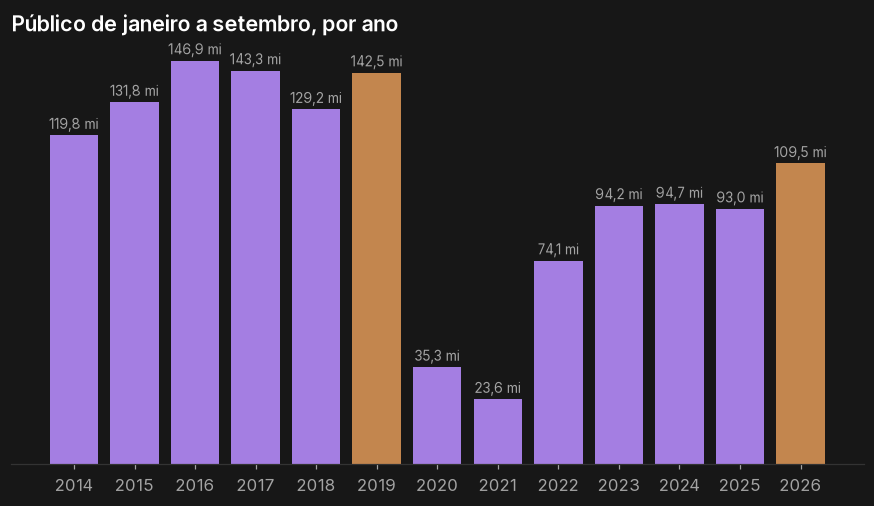

In [19]:
grafico_anos(anual["publico_jan_set"], "Público de janeiro a setembro, por ano", mi, destaques=[2019, 2026])

Não voltou. Em 2025 foram 115 milhões de espectadores, 65% de 2019, menos até do que em 2024. Olhando só janeiro a setembro, o mercado ficou parado em torno de 94 milhões de 2023 a 2025, dois terços de 2019.

2026 é o primeiro salto em três anos: 109,5 milhões de janeiro a setembro, 77% de 2019. Mesmo assim, fica abaixo de todos os anos entre 2014 e 2019. O pior deles, 2014, teve 120 milhões nos mesmos meses.

Ainda falta mais ou menos um terço do público. Agora quero entender de onde vem essa diferença.

### Faltam salas e sessões ou falta gente em cada sessão?

O público de um ano é o número de sessões vezes a média de pessoas por sessão. Separando as duas coisas, dá para ver se o problema é de oferta (menos salas e sessões) ou de demanda (sessões mais vazias). Aqui uso a fonte das exibidoras, que registra cada sessão, de 2017 em diante.

In [20]:
oferta = consulta("""
    SELECT year(dia) AS ano, count(DISTINCT registro_sala) AS n_salas, count(*) AS n_sessoes,
           sum(publico) AS publico, sum(CASE WHEN publico = 0 THEN 1 ELSE 0 END) AS n_sessoes_vazias
    FROM e GROUP BY ano ORDER BY ano
""").set_index("ano")
oferta["publico_por_sessao"] = oferta["publico"] / oferta["n_sessoes"]
oferta["pct_vazias"] = oferta["n_sessoes_vazias"] / oferta["n_sessoes"]
oferta.style.format({"n_salas": br, "n_sessoes": br, "publico": mi, "n_sessoes_vazias": br,
                     "publico_por_sessao": lambda v: br(v, 1), "pct_vazias": pct})

,n_salas,n_sessoes,publico,n_sessoes_vazias,publico_por_sessao,pct_vazias
ano,,,,,,
2017,3.241,4.188.255,"177,7 mi",138.518,"42,4","3,3%"
2018,3.369,4.345.880,"161,7 mi",187.682,"37,2","4,3%"
2019,3.601,4.397.757,"174,5 mi",154.898,"39,7","3,5%"
2020,3.519,1.370.446,"39,2 mi",94.541,"28,6","6,9%"
2021,3.309,2.323.137,"50,9 mi",203.567,"21,9","8,8%"
2022,3.446,3.727.569,"96,4 mi",237.039,"25,9","6,4%"
2023,3.483,4.026.661,"116,1 mi",234.405,"28,8","5,8%"
2024,3.616,4.341.525,"127,2 mi",326.064,"29,3","7,5%"
2025,3.595,4.394.220,"114,3 mi",402.627,"26,0","9,2%"


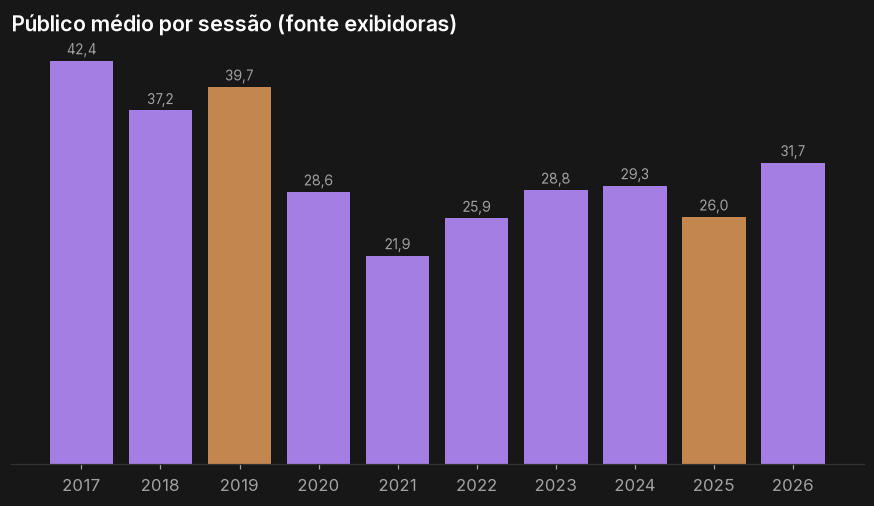

In [21]:
grafico_anos(oferta["publico_por_sessao"], "Público médio por sessão (fonte exibidoras)", lambda v: br(v, 1), destaques=[2019, 2025])

A oferta voltou e a demanda não. Em 2025 havia praticamente as mesmas salas (3.595, contra 3.601 em 2019) e as mesmas sessões (4,39 milhões, contra 4,40 milhões) de antes da pandemia. O que caiu foi a média de gente por sessão: 26 pessoas em 2025, contra 40 em 2019 (−34%). As sessões sem nenhum espectador quase triplicaram, de 3,5% para 9,2%.

Então a diferença inteira está no público por sessão. Em 2026 essa média subiu para 32, e é isso que explica a melhora do ano. As próximas perguntas tentam entender por que cada sessão atrai menos gente.

## 1. A recuperação depende de poucos sucessos?

Aqui vejo quanto do público do ano ficou com os 3 e os 10 filmes mais vistos, e quantos filmes passaram de 1 milhão de espectadores. Só entram filmes (código B ou E); eventos e mostras ficam de fora.

Primeiro puxo o público de cada filme em cada ano. Essa tabela é pequena (alguns milhares de linhas), então o resto das contas faço no pandas mesmo.

In [22]:
filmes_ano = consulta("""
    SELECT year(dia) AS ano, cpb_roe, tipo, sum(publico) AS publico
    FROM d WHERE tipo IN ('B', 'E')
    GROUP BY ano, cpb_roe, tipo
""")
filmes_ano = filmes_ano.merge(nomes, on="cpb_roe", how="left")
filmes_ano = filmes_ano.sort_values(["ano", "publico"], ascending=[True, False])
filmes_ano["posicao"] = filmes_ano.groupby("ano").cumcount() + 1   # 1 = mais visto do ano
filmes_ano.head()

,ano,cpb_roe,tipo,publico,filme,posicao
2201,2014,E1402308800000,E,6373078.0,A CULPA É DAS ESTRELAS,1
5399,2014,E1500120000000,E,5796471.0,MALÉVOLA,2
7521,2014,E1402667700000,E,5224098.0,RIO 2,3
22,2014,E1500054300000,E,5002937.0,X-MEN: DIAS DE UM FUTURO ESQUECIDO,4
4326,2014,E1402510400000,E,4906081.0,NOÉ,5


In [23]:
conc = filmes_ano.groupby("ano").agg(n_filmes=("cpb_roe", "count"), publico=("publico", "sum"))
conc["n_filmes_1mi"] = filmes_ano[filmes_ano["publico"] >= 1_000_000].groupby("ano")["cpb_roe"].count()
conc["pct_3_maiores"] = filmes_ano[filmes_ano["posicao"] <= 3].groupby("ano")["publico"].sum() / conc["publico"]
conc["pct_10_maiores"] = filmes_ano[filmes_ano["posicao"] <= 10].groupby("ano")["publico"].sum() / conc["publico"]
conc.style.format({"publico": mi, "pct_3_maiores": pct, "pct_10_maiores": pct})

,n_filmes,publico,n_filmes_1mi,pct_3_maiores,pct_10_maiores
ano,,,,,
2014,670,"156,9 mi",43,"11,1%","32,0%"
2015,795,"169,2 mi",45,"17,1%","36,9%"
2016,762,"184,9 mi",47,"15,9%","38,0%"
2017,717,"181,8 mi",43,"14,2%","39,7%"
2018,714,"163,3 mi",34,"22,3%","45,8%"
2019,690,"177,6 mi",36,"25,7%","50,9%"
2020,544,"39,4 mi",8,"50,4%","76,8%"
2021,469,"53,0 mi",11,"38,4%","64,9%"
2022,568,"97,4 mi",21,"22,5%","59,5%"


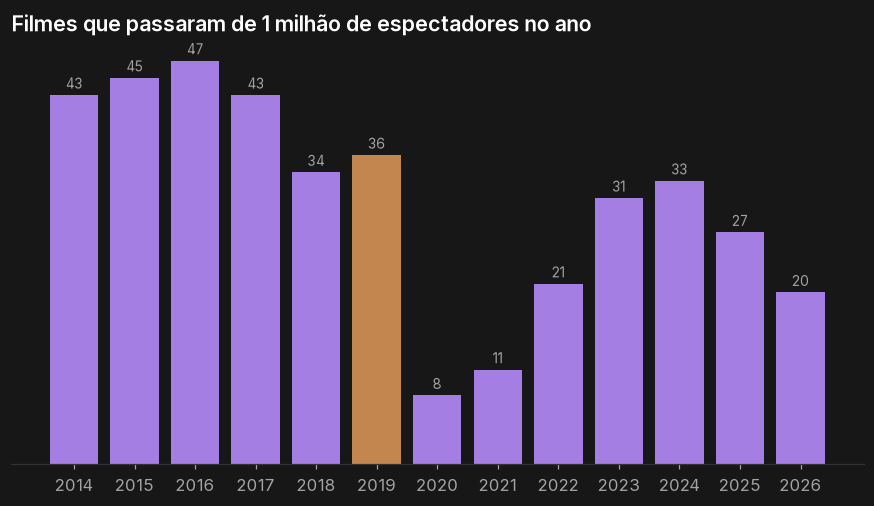

In [24]:
grafico_anos(conc["n_filmes_1mi"], "Filmes que passaram de 1 milhão de espectadores no ano", br)

Eu esperava ver o mercado mais concentrado, mas não é o caso: os 10 maiores filmes levaram 44% do público em 2025, contra 51% em 2019. O que mudou foi o tamanho dos sucessos. Em 2025 houve mais filmes em cartaz (759, contra 690 em 2019), mas só 27 passaram de 1 milhão de espectadores. Em 2019 foram 36, e entre 2014 e 2017, de 43 a 47 por ano.

2026 foge da regra. De janeiro a setembro, os 10 maiores ficaram com 62% do público, a maior concentração desde a pandemia, ou seja, a melhora de 2026 veio de poucos filmes muito grandes. Como o ano ainda não acabou, essa fatia pode mudar.

Os cinco maiores filmes de 2019, 2025 e 2026:

In [25]:
top5 = filmes_ano[filmes_ano["ano"].isin([2019, 2025, 2026]) & (filmes_ano["posicao"] <= 5)]
top5_nomes = top5.pivot(index="posicao", columns="ano", values="filme")
top5_publico = top5.pivot(index="posicao", columns="ano", values="publico").map(mi)
top5_nomes.join(top5_publico, rsuffix=" (público)")

ano,2019,2025,2026,2019 (público),2025 (público),2026 (público)
posicao,,,,,,
1,VINGADORES: ULTIMATO,LILO & STITCH,HOMEM-ARANHA: UM NOVO DIA,"19,7 mi","10,4 mi","18,8 mi"
2,O REI LEÃO,COMO TREINAR O SEU DRAGÃO,TOY STORY 5,"16,2 mi","6,0 mi","8,3 mi"
3,CORINGA,UM FILME MINECRAFT,MICHAEL,"9,7 mi","5,4 mi","7,4 mi"
4,CAPITÃ MARVEL,INVOCAÇÃO DO MAL 4: O ÚLTIMO RITUAL,O DIABO VESTE PRADA 2,"9,0 mi","4,7 mi","7,0 mi"
5,TOY STORY 4,ZOOTOPIA 2,A ODISSEIA,"8,0 mi","4,5 mi","5,3 mi"


In [26]:
filmes_ano["grupo"] = "demais filmes"
filmes_ano.loc[filmes_ano["posicao"] <= 10, "grupo"] = "10 maiores filmes"

dois_anos = filmes_ano[filmes_ano["ano"].isin([2019, 2025])]
partes = dois_anos.pivot_table(index="grupo", columns="ano", values="publico", aggfunc="sum")
partes["n_filmes_2025"] = dois_anos[dois_anos["ano"] == 2025].groupby("grupo")["cpb_roe"].count()
partes["perda"] = partes[2019] - partes[2025]
partes["pct_da_perda"] = partes["perda"] / partes["perda"].sum()
partes.style.format({2019: mi, 2025: mi, "perda": mi, "pct_da_perda": pct})

ano,2019,2025,n_filmes_2025,perda,pct_da_perda
grupo,,,,,
10 maiores filmes,"90,3 mi","50,5 mi",10,"39,8 mi","63,9%"
demais filmes,"87,3 mi","64,7 mi",749,"22,5 mi","36,1%"


A perda está principalmente nos sucessos. O maior filme de 2025, *Lilo & Stitch*, teve 10,4 milhões de espectadores, metade de *Vingadores: Ultimato* em 2019. Entre 2019 e 2025, os 10 maiores filmes perderam 39,8 milhões de espectadores (−44%), enquanto os outros cerca de 750 filmes perderam 22,5 milhões (−26%). Uns dois terços da diferença estão nesses 10 filmes.

O cinema voltou a ter salas e títulos. O que falta são os filmes-evento que levavam multidões, e isso combina com o salto de 2026, puxado por *Homem-Aranha: Um Novo Dia* (18,8 milhões até setembro).

## 2. Quanto do público vai para filmes brasileiros?

Calculo a fatia dos filmes brasileiros (código B) no público de filmes de cada ano e procuro o maior filme brasileiro de cada ano. Reaproveito a tabela `filmes_ano` da pergunta anterior.

In [27]:
brasileiros = filmes_ano[filmes_ano["tipo"] == "B"]

nacional = brasileiros.groupby("ano").agg(n_filmes_brasileiros=("cpb_roe", "count"), publico_brasileiro=("publico", "sum"))
nacional["pct_do_publico"] = nacional["publico_brasileiro"] / conc["publico"]

# filmes_ano já está ordenado do maior para o menor, então o primeiro de cada ano é o maior
maior = brasileiros.drop_duplicates("ano").set_index("ano")
nacional["maior_filme_brasileiro"] = maior["filme"]
nacional["publico_do_maior"] = maior["publico"]
nacional.style.format({"publico_brasileiro": mi, "pct_do_publico": pct, "publico_do_maior": mi})

,n_filmes_brasileiros,publico_brasileiro,pct_do_publico,maior_filme_brasileiro,publico_do_maior
ano,,,,,
2014,176,"19,2 mi","12,2%",ATÉ QUE A SORTE NOS SEPARE 2,"3,2 mi"
2015,210,"21,4 mi","12,6%",LOUCAS PRA CASAR,"3,7 mi"
2016,217,"30,0 mi","16,2%",OS DEZ MANDAMENTOS,"11,3 mi"
2017,229,"18,3 mi","10,1%",MINHA MÃE É UMA PEÇA 2,"6,5 mi"
2018,255,"24,2 mi","14,8%",NADA A PERDER,"12,2 mi"
2019,253,"24,2 mi","13,6%",NADA A PERDER 2,"6,2 mi"
2020,138,"8,7 mi","22,1%",MINHA MÃE É UMA PEÇA 3,"8,5 mi"
2021,157,"0,7 mi","1,4%",MARIGHELLA,"0,3 mi"
2022,221,"4,5 mi","4,6%",TURMA DA MÔNICA: LIÇÕES,"0,8 mi"


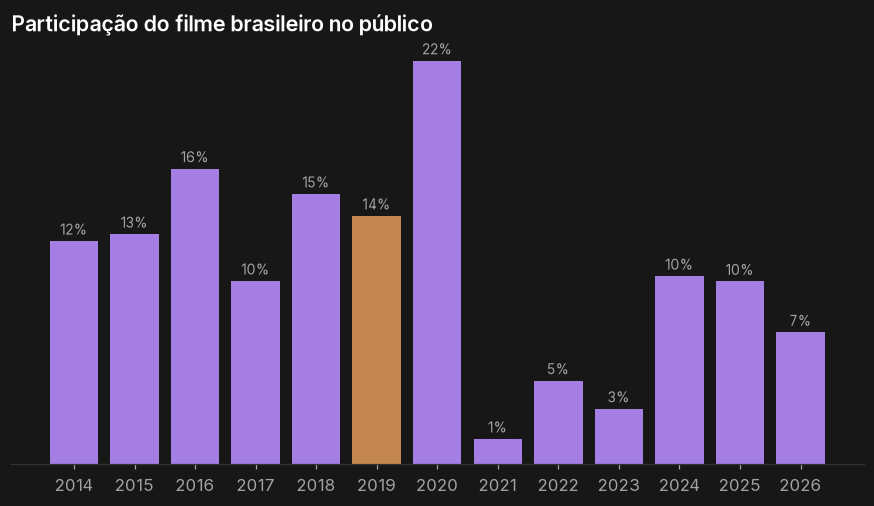

In [28]:
grafico_anos(nacional["pct_do_publico"], "Participação do filme brasileiro no público", lambda v: pct(v, 0))

O filme brasileiro recuperou a fatia, mas não o público. De 2014 a 2019 ele ficava entre 10% e 16% do público. Na pandemia, caiu para 1% a 5% entre 2021 e 2023. O pico de 22% em 2020 engana: *Minha Mãe é uma Peça 3* estreou no fim de 2019 e encheu as salas antes do fechamento.

Em 2024 e 2025 a fatia voltou para perto de 10%. Só que, em número de pessoas, 2025 teve 11,6 milhões, menos da metade dos 24,2 milhões de 2019. E cada ano depende de um sucesso só: *Ainda Estou Aqui* em 2024 e *O Auto da Compadecida 2* em 2025 fizeram cerca de 3 milhões cada, quando os sucessos de antes passavam de 6 a 12 milhões (*Os Dez Mandamentos*, *Nada a Perder*).

É a mesma falta de grandes sucessos da pergunta 1, agora no cinema nacional.

## 3. Faltam salas e sessões ou falta gente nas sessões?

A pergunta principal já mostrou, pelas exibidoras, que salas e sessões voltaram. Aqui confiro pela fonte das distribuidoras, que não tem buraco de cobertura antes da pandemia. Nessa fonte, uma exibição é um filme passando numa sala num dia.

In [29]:
oferta_d = consulta("""
    SELECT year(dia) AS ano, count(DISTINCT registro_sala) AS n_salas, count(*) AS n_exibicoes,
           sum(publico) AS publico, count(DISTINCT cpb_roe) AS n_filmes
    FROM d WHERE year(dia) BETWEEN 2016 AND 2025
    GROUP BY ano ORDER BY ano
""").set_index("ano")
oferta_d["publico_por_exibicao"] = oferta_d["publico"] / oferta_d["n_exibicoes"]
oferta_d.style.format({"n_salas": br, "n_exibicoes": br, "publico": mi, "n_filmes": br, "publico_por_exibicao": lambda v: br(v, 1)})

,n_salas,n_exibicoes,publico,n_filmes,publico_por_exibicao
ano,,,,,
2016,3.641,1.723.763,"184,9 mi",762,"107,2"
2017,3.359,1.792.220,"181,8 mi",717,"101,4"
2018,3.476,1.814.115,"163,3 mi",714,"90,0"
2019,3.749,1.848.152,"177,6 mi",690,"96,1"
2020,3.729,590.504,"39,4 mi",544,"66,6"
2021,3.503,1.176.195,"53,0 mi",469,"45,1"
2022,3.564,1.735.671,"97,4 mi",568,"56,1"
2023,3.601,1.942.319,"117,0 mi",641,"60,2"
2024,3.710,2.094.014,"128,1 mi",695,"61,2"


A outra fonte confirma. As salas ativas em 2025 (3.769) são as mesmas de 2019 (3.749), e as exibições até cresceram 17% (2,17 milhões, contra 1,85 milhão), porque cada sala passou a alternar mais filmes por dia. Já o público por exibição caiu de 96 para 53 (−45%).

A oferta não só voltou como aumentou, então o problema é de demanda. Fui ver em que horário ficam as sessões vazias. Puxo as sessões de 2025 por hora e depois agrupo em períodos no pandas (vou usar a mesma tabela de novo na pergunta 7).

In [30]:
sessoes_2025 = consulta("""
    SELECT hour(sessao) AS hora, count(*) AS n_sessoes, sum(publico) AS publico,
           sum(CASE WHEN publico = 0 THEN 1 ELSE 0 END) AS n_vazias
    FROM e WHERE year(dia) = 2025
    GROUP BY hora ORDER BY hora
""")
sessoes_2025.head()

,hora,n_sessoes,publico,n_vazias
0,0,129,3711.0,42.0
1,1,11,234.0,8.0
2,2,6,7.0,5.0
3,3,15,243.0,12.0
4,4,2,60.0,0.0


In [31]:
def periodo(hora):
    if hora < 12:
        return "1. manhã (até 12h)"
    elif hora < 18:
        return "2. tarde (12h–18h)"
    else:
        return "3. noite (18h+)"

sessoes_2025["periodo"] = sessoes_2025["hora"].apply(periodo)

In [32]:
vazias = sessoes_2025.groupby("periodo")[["n_sessoes", "publico", "n_vazias"]].sum()
vazias["pct_sem_publico"] = vazias["n_vazias"] / vazias["n_sessoes"]
vazias["publico_medio"] = vazias["publico"] / vazias["n_sessoes"]
vazias.style.format({"n_sessoes": br, "publico": mi, "n_vazias": br, "pct_sem_publico": pct, "publico_medio": lambda v: br(v, 1)})

,n_sessoes,publico,n_vazias,pct_sem_publico,publico_medio
periodo,,,,,
1. manhã (até 12h),28.007,"0,5 mi",11.802,"42,1%","16,1"
2. tarde (12h–18h),2.209.206,"47,5 mi",273.420,"12,4%","21,5"
3. noite (18h+),2.157.007,"66,3 mi",117.405,"5,4%","30,8"


As sessões vazias ficam fora do horário nobre. De manhã, 42% das sessões não tiveram ninguém, mas elas são poucas (28 mil, menos de 1% do total). À tarde, 12% ficaram vazias. À noite, só 5%, com 31 pessoas por sessão em média.

A tarde é o período com mais sessões (2,2 milhões em 2025) e é onde mais sobra lugar. Se fosse para rever a programação de algum horário, eu começaria por ela.

## 4. Em que lugares o público não voltou?

Para cada UF, calculo o público de 2025 como % do de 2019 e quantos espectadores faltam para voltar ao nível de 2019. A linha tracejada no gráfico é a média do Brasil (65%). Público por habitante ficou de fora, porque precisaria da população do IBGE, que não está nesse dataset.

In [33]:
uf_ano = consulta("""
    SELECT uf, year(dia) AS ano, sum(publico) AS publico, count(DISTINCT registro_sala) AS salas
    FROM d WHERE uf IS NOT NULL AND year(dia) IN (2019, 2025)
    GROUP BY uf, ano
""")
uf = uf_ano.pivot(index="uf", columns="ano", values="publico")
uf.columns = ["publico_2019", "publico_2025"]
uf["n_salas_2025"] = uf_ano[uf_ano["ano"] == 2025].set_index("uf")["salas"]

In [34]:
uf["pct_recuperado"] = uf["publico_2025"] / uf["publico_2019"]
uf["faltam"] = uf["publico_2019"] - uf["publico_2025"]
uf["pct_da_diferenca"] = uf["faltam"] / uf["faltam"].sum()

# as 8 UFs onde mais falta público
uf.sort_values("faltam", ascending=False).head(8).style.format(
    {"publico_2019": mi, "publico_2025": mi, "faltam": mi, "pct_recuperado": pct, "pct_da_diferenca": pct})

,publico_2019,publico_2025,n_salas_2025,pct_recuperado,faltam,pct_da_diferenca
uf,,,,,,
SP,"60,0 mi","37,4 mi",1165,"62,3%","22,6 mi","36,2%"
RJ,"24,9 mi","14,1 mi",410,"56,8%","10,7 mi","17,2%"
MG,"12,4 mi","7,9 mi",290,"63,5%","4,5 mi","7,3%"
PR,"9,6 mi","6,4 mi",249,"67,3%","3,1 mi","5,0%"
RS,"8,1 mi","5,0 mi",193,"62,5%","3,0 mi","4,9%"
DF,"5,4 mi","3,5 mi",97,"64,6%","1,9 mi","3,1%"
BA,"6,3 mi","4,7 mi",149,"74,9%","1,6 mi","2,5%"
PE,"6,3 mi","4,8 mi",121,"76,5%","1,5 mi","2,4%"


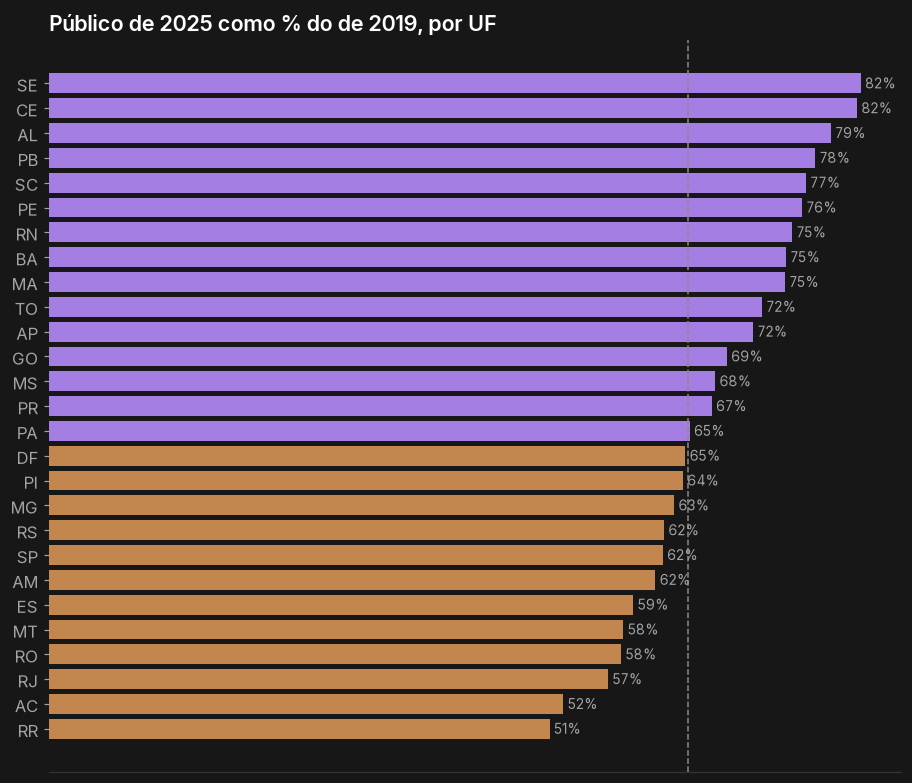

In [35]:
media_brasil = anual.loc[2025, "pct_2019_ano"]
grafico_lista(uf["pct_recuperado"], "Público de 2025 como % do de 2019, por UF", lambda v: pct(v, 0), referencia=media_brasil)

A recuperação foi bem desigual. O Nordeste e Santa Catarina se saíram melhor: Sergipe e Ceará estão em 82% de 2019, e Alagoas, Paraíba, Santa Catarina e Pernambuco ficam entre 76% e 79%. Os grandes mercados do Sudeste ficaram abaixo da média, com São Paulo em 62% e o Rio de Janeiro em 57%, o pior entre os grandes.

Como SP e RJ concentravam quase metade do público, os dois sozinhos respondem por mais da metade da diferença do país (22,6 milhões e 10,7 milhões de espectadores a menos). Roraima e Acre estão perto de 50% de 2019, mas pesam pouco no total.

Agrupando por região e separando as capitais do interior:

In [36]:
uf_com_regiao = uf.reset_index().merge(regiao, on="uf")
reg = uf_com_regiao.groupby("regiao")[["publico_2019", "publico_2025"]].sum()
reg["n_ufs"] = uf_com_regiao.groupby("regiao")["uf"].count()
reg["pct_recuperado"] = reg["publico_2025"] / reg["publico_2019"]
reg["faltam"] = reg["publico_2019"] - reg["publico_2025"]
reg["pct_da_diferenca"] = reg["faltam"] / reg["faltam"].sum()
reg.sort_values("pct_recuperado").style.format(
    {"publico_2019": mi, "publico_2025": mi, "faltam": mi, "pct_recuperado": pct, "pct_da_diferenca": pct})

,publico_2019,publico_2025,n_ufs,pct_recuperado,faltam,pct_da_diferenca
regiao,,,,,,
SUDESTE,"100,5 mi","61,3 mi",4,"61,0%","39,2 mi","62,8%"
NORTE,"11,0 mi","6,9 mi",7,"62,5%","4,1 mi","6,6%"
CENTRO-OESTE,"14,3 mi","9,4 mi",4,"65,2%","5,0 mi","8,0%"
SUL,"23,7 mi","16,1 mi",3,"68,1%","7,6 mi","12,1%"
NORDESTE,"28,1 mi","21,6 mi",9,"76,8%","6,5 mi","10,4%"


In [37]:
cap = consulta("""
    SELECT CASE WHEN strip_accents(d.municipio) = capital.capital THEN 'capitais' ELSE 'interior' END AS lugar,
           year(dia) AS ano, count(DISTINCT registro_sala) AS salas, sum(publico) AS publico
    FROM d JOIN capital USING (uf)
    WHERE year(dia) IN (2019, 2025)
    GROUP BY lugar, ano
""")
cap = cap.pivot(index="lugar", columns="ano", values=["salas", "publico"])
cap.columns = ["n_salas_2019", "n_salas_2025", "publico_2019", "publico_2025"]
cap["pct_recuperado"] = cap["publico_2025"] / cap["publico_2019"]

In [38]:
cap.style.format({"n_salas_2019": br, "n_salas_2025": br, "publico_2019": mi, "publico_2025": mi, "pct_recuperado": pct})

,n_salas_2019,n_salas_2025,publico_2019,publico_2025,pct_recuperado
lugar,,,,,
capitais,1.654,1.561,"91,4 mi","57,2 mi","62,6%"
interior,2.095,2.208,"86,1 mi","58,0 mi","67,4%"


O Sudeste é onde o público menos voltou (61% de 2019) e concentra 63% da diferença. O Nordeste é a região que mais voltou (77%).

Entre capitais e interior, as capitais recuperaram menos (63%, contra 67%) e ainda perderam salas (de 1.654 para 1.561), enquanto o interior ganhou (de 2.095 para 2.208). Em 2025, o interior já teve mais público que as capitais.

Os dados mostram onde o público não voltou, mas não explicam por quê. Trabalho remoto ou preço do ingresso nas capitais são hipóteses razoáveis, só que eu precisaria de outros dados para testar.

## 5. Quais empresas ganharam e quais perderam espaço?

Começo pelas distribuidoras, vendo quanto do público ficou com as 5 maiores em cada ano. Aqui uso as linhas do jeito que vieram (tabela `t`, e não `d`), porque cada distribuidora responde pelo público que informou. Quando duas dividem um filme, a mesma exibição conta para as duas, mas isso quase não mexe nas fatias.

In [39]:
dist_ano = consulta("""
    SELECT year(data_exibicao) AS ano, cnpj_distribuidora, sum(publico) AS publico
    FROM t
    WHERE fonte = 'distribuidor' AND year(data_exibicao) BETWEEN 2014 AND 2025
    GROUP BY ano, cnpj_distribuidora
""")
dist_ano = dist_ano.merge(nomes_distribuidoras, on="cnpj_distribuidora", how="left")
dist_ano = dist_ano.sort_values(["ano", "publico"], ascending=[True, False])

In [40]:
dist = dist_ano.groupby("ano").agg(n_distribuidoras=("cnpj_distribuidora", "count"), publico=("publico", "sum"))
dist["publico_5_maiores"] = dist_ano.groupby("ano").head(5).groupby("ano")["publico"].sum()
dist["pct_5_maiores"] = dist["publico_5_maiores"] / dist["publico"]
dist.style.format({"publico": mi, "publico_5_maiores": mi, "pct_5_maiores": pct})

,n_distribuidoras,publico,publico_5_maiores,pct_5_maiores
ano,,,,
2014,73,"156,9 mi","113,6 mi","72,4%"
2015,90,"169,2 mi","137,8 mi","81,4%"
2016,105,"184,9 mi","157,2 mi","85,0%"
2017,107,"181,8 mi","136,7 mi","75,2%"
2018,105,"163,3 mi","124,1 mi","76,0%"
2019,84,"179,3 mi","145,8 mi","81,4%"
2020,52,"39,4 mi","32,4 mi","82,4%"
2021,51,"53,0 mi","50,7 mi","95,6%"
2022,79,"97,4 mi","90,2 mi","92,6%"


In [41]:
dois_anos = dist_ano[dist_ano["ano"].isin([2019, 2025])]
lideres = dois_anos.pivot_table(index="distribuidora", columns="ano", values="publico", aggfunc="sum")
lideres[2019] = lideres[2019] / dist.loc[2019, "publico"]
lideres[2025] = lideres[2025] / dist.loc[2025, "publico"]

# as 8 maiores, olhando a maior fatia que cada uma teve em 2019 ou em 2025
lideres["maior_fatia"] = lideres[[2019, 2025]].max(axis=1)
lideres = lideres.sort_values("maior_fatia", ascending=False).head(8)
lideres[[2019, 2025]].style.format(pct, na_rep="—")

ano,2019,2025
distribuidora,,
THE WALT DISNEY COMPANY (BRASIL) LTDA.,"42,2%","33,2%"
WARNER BROS. (SOUTH) INC.,"13,7%","35,2%"
SM DISTRIBUIDORA DE FILMES LTDA,"9,3%","6,4%"
COLUMBIA TRISTAR FILMES DO BRASIL LTDA,"7,9%","8,5%"
UNIVERSAL PICTURES INTERNATIONAL BRAZIL LTDA.,"8,2%",—
PARAMOUNT PICTURES BRASIL DISTRIBUIDORA DE FILMES LTDA,"2,7%","6,6%"
FREESPIRIT DISTRIBUIDORA DE FILMES LTDA.,"5,0%","0,1%"
FOX FILM DO BRASIL LTDA,"4,5%",—


A distribuição ficou mais concentrada. As 5 maiores passaram de 81% do público em 2019 para 90% em 2025, e estão acima de 88% desde 2021.

No topo, a Disney perdeu a liderança folgada que tinha (de 42% para 33%), e a Warner quase triplicou a fatia (de 14% para 35%), passando a dividir o primeiro lugar. Entre as nacionais, a SM encolheu (de 9% para 6%) e a Freespirit praticamente sumiu (de 5% para 0,1%), sem nenhuma independente ocupando esse espaço.

A Fox, que foi incorporada pela Disney, e a Universal não aparecem com público em 2025. Então parte dessas mudanças vem de troca de quem distribui os filmes de cada estúdio, e não de ganho real de público.

Agora os grupos exibidores, pela fonte das exibidoras. A base não traz o nome dos grupos, então uso a razão social mais frequente de cada um. "Independentes" são as salas sem grupo.

In [42]:
redes_ano = consulta("""
    SELECT year(dia) AS ano, grupo, sum(publico) AS publico, count(DISTINCT registro_sala) AS n_salas
    FROM e WHERE year(dia) IN (2019, 2025)
    GROUP BY ano, grupo
""")
redes_ano = redes_ano.merge(nomes_grupos, on="grupo", how="left")
redes_ano["nome_grupo"] = redes_ano["nome_grupo"].fillna("independentes (sem grupo)")

In [43]:
redes = redes_ano.pivot_table(index="nome_grupo", columns="ano", values="publico", aggfunc="sum")
redes["n_salas_2025"] = redes_ano[redes_ano["ano"] == 2025].groupby("nome_grupo")["n_salas"].sum()
redes["pct_2025"] = redes[2025] / redes[2025].sum()
redes["pct_recuperado"] = redes[2025] / redes[2019]

# as 7 maiores redes de 2019
redes = redes.sort_values(2019, ascending=False).head(7)
redes.style.format({2019: mi, 2025: mi, "n_salas_2025": br, "pct_2025": pct, "pct_recuperado": pct})

ano,2019,2025,n_salas_2025,pct_2025,pct_recuperado
nome_grupo,,,,,
CINEMARK BRASIL S.A,"42,3 mi","26,7 mi",619,"23,4%","63,1%"
CINEPOLIS OPERADORA DE CINEMAS DO BRASIL LTDA,"23,0 mi","14,5 mi",414,"12,7%","63,1%"
EMPRESA CINEMAS SÃO LUIZ S/A,"14,6 mi","9,2 mi",200,"8,1%","62,9%"
MSA EMPRESA CINEMATOGRÁFICA LTDA,"13,9 mi","7,8 mi",163,"6,8%","55,9%"
REDECINE BRA CINEMATOGRÁFICA S.A.,"8,0 mi","5,7 mi",183,"4,9%","70,9%"
UNITED CINEMAS INTERNATIONAL BRASIL LTDA.,"7,7 mi","6,1 mi",144,"5,3%","78,7%"
independentes (sem grupo),"7,6 mi","6,0 mi",337,"5,3%","79,1%"


Na exibição, quase nada mudou de dono. A Cinemark segue na frente, com 23% do público (24% em 2019), seguida da Cinépolis (13%) e da Cinemas São Luiz (8%). As grandes redes recuperaram de forma parecida, entre 56% e 71% de 2019, perto da média do mercado (Cinemark, Cinépolis e São Luiz estão as três em 63%). Quem se saiu melhor foram as salas independentes e a United Cinemas, as duas em 79%.

Resumindo: na exibição, a queda atingiu todo mundo mais ou menos igual. Na distribuição, ela deixou o mercado mais nas mãos dos grandes estúdios.

## 6. Como é a vida de um filme em cartaz?

Pego os filmes com pelo menos 100 mil espectadores. Considero como estreia o primeiro dia em que o filme esteve em pelo menos um quarto do seu número máximo de salas, para não confundir pré-estreia em poucas salas com lançamento. Para cada filme, calculo:
- quanto do público total veio nos 7 primeiros dias;
- quantos dias ele levou para chegar a 90% do público total;
- em quantas salas ele esteve no pico.

Começo puxando, para cada filme e cada dia, em quantas salas ele passou e quanto público fez.

In [44]:
filme_dia = consulta("""
    SELECT cpb_roe, dia, count(*) AS salas, sum(publico) AS publico
    FROM d WHERE tipo IN ('B', 'E')
    GROUP BY cpb_roe, dia
""")
print(len(filme_dia), "linhas (filme x dia)")

295969 linhas (filme x dia)


In [45]:
resumo = filme_dia.groupby("cpb_roe").agg(total=("publico", "sum"), pico=("salas", "max"))
resumo = resumo[resumo["total"] >= 100_000]   # só filmes com 100 mil espectadores ou mais

vida_dia = filme_dia.merge(resumo, on="cpb_roe")
estreia = vida_dia[vida_dia["salas"] >= 0.25 * vida_dia["pico"]].groupby("cpb_roe")["dia"].min()
vida_dia["estreia"] = vida_dia["cpb_roe"].map(estreia)
vida_dia["dias_desde_estreia"] = (vida_dia["dia"] - vida_dia["estreia"]).dt.days
print(len(resumo), "filmes")

1208 filmes


In [46]:
vida_dia = vida_dia.sort_values(["cpb_roe", "dia"])
vida_dia["acumulado"] = vida_dia.groupby("cpb_roe")["publico"].cumsum()

primeira_semana = vida_dia[vida_dia["dias_desde_estreia"].between(0, 6)].groupby("cpb_roe")["publico"].sum()
chegou_90 = vida_dia[vida_dia["acumulado"] >= 0.9 * vida_dia["total"]].groupby("cpb_roe")["dias_desde_estreia"].min()

resumo["ano_estreia"] = estreia.dt.year
resumo["pct_7_dias"] = primeira_semana / resumo["total"]
resumo["dias_ate_90"] = chegou_90

In [47]:
vida = resumo[resumo["ano_estreia"].between(2015, 2025)].groupby("ano_estreia").agg(
    n_filmes=("total", "count"),
    pct_7_dias=("pct_7_dias", "median"),
    dias_ate_90=("dias_ate_90", "median"),
    salas_no_pico=("pico", "median"),
)
vida.style.format({"pct_7_dias": pct, "dias_ate_90": br, "salas_no_pico": br})

,n_filmes,pct_7_dias,dias_ate_90,salas_no_pico
ano_estreia,,,,
2015,117,"43,8%",23,345
2016,125,"46,2%",20,400
2017,122,"46,3%",22,484
2018,114,"45,3%",19,460
2019,110,"46,3%",20,538
2020,33,"42,1%",25,512
2021,50,"42,3%",24,803
2022,73,"41,5%",21,717
2023,85,"46,6%",21,842


(Os valores são medianas dos filmes com 100 mil espectadores ou mais.)

A curva de um filme continua a mesma: ele faz uns 46% a 48% do público na primeira semana e chega a 90% do público em torno de 20 dias. Não vi sinal de que os filmes estejam saindo de cartaz mais cedo depois da pandemia.

O que mudou foi a largura da estreia. O filme típico chegou a cerca de 770 salas no pico em 2025, contra 538 em 2019. Ao mesmo tempo, houve menos filmes desse porte (94 em 2025, contra 110 em 2019). Com o mesmo número de salas no país, faz sentido que cada sucesso ocupe mais telas.

Para a pergunta principal, isso quer dizer que o lançamento ficou concentrado em poucos títulos grandes. Quando um deles não emplaca, sobra muita sala para pouca gente.

## 7. Quando o público vai ao cinema?

Começo pelo dia da semana, com o público médio por dia de 2023 a 2025. A coluna `n_dias` mostra quantos dias entraram em cada média, e o índice compara cada dia com a média da semana (100 = média).

In [48]:
por_dia = consulta("""
    SELECT dia, sum(publico) AS publico
    FROM d WHERE year(dia) BETWEEN 2023 AND 2025
    GROUP BY dia
""")
por_dia["dia_semana"] = por_dia["dia"].dt.dayofweek   # 0 = segunda, 6 = domingo
semana = por_dia.groupby("dia_semana")["publico"].agg(n_dias="count", publico_medio="mean")
semana.index = ["segunda", "terça", "quarta", "quinta", "sexta", "sábado", "domingo"]
semana["indice"] = 100 * semana["publico_medio"] / semana["publico_medio"].mean()
semana.style.format({"publico_medio": br, "indice": br})

,n_dias,publico_medio,indice
segunda,157,269.533,82
terça,157,246.230,75
quarta,157,265.107,81
quinta,156,268.772,82
sexta,156,292.345,89
sábado,156,525.327,160
domingo,157,435.204,132


Sábado é o dia mais forte, com quase o dobro da média dos dias úteis, e depois vem o domingo. A quinta, que é dia de estreia, não se destaca: o público dos lançamentos chega mesmo no fim de semana. A terça é o dia mais fraco.

Depois, os meses. Como cada mês tem um número diferente de dias, comparo o público por dia de cada mês com a média do próprio ano (1 = média do ano). Faço isso ano a ano, porque um pico só conta como sazonal se aparecer em todos os anos.

In [49]:
por_mes = consulta("""
    SELECT year(dia) AS ano, month(dia) AS mes, sum(publico) AS publico
    FROM d WHERE year(dia) BETWEEN 2022 AND 2025
    GROUP BY ano, mes
""")
por_mes["dias_no_mes"] = [calendar.monthrange(ano, mes)[1] for ano, mes in zip(por_mes["ano"], por_mes["mes"])]
por_mes["por_dia"] = por_mes["publico"] / por_mes["dias_no_mes"]
por_mes["indice"] = por_mes["por_dia"] / por_mes.groupby("ano")["por_dia"].transform("mean")
sazonal = por_mes.pivot(index="mes", columns="ano", values="indice")

In [50]:
def mapa_calor(tabela, titulo):
    # mesma escala do dashboard: aço (abaixo da média), cinza (na média), pêssego (acima)
    escala = LinearSegmentedColormap.from_list("pastel", ["#094864", "#262626", "#5E3811"])
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(tabela.values, cmap=escala, vmin=0.5, vmax=1.5, aspect="auto")   # 1 fica no meio da escala
    ax.set(title=titulo, xticks=range(len(tabela.columns)), xticklabels=tabela.columns, yticks=range(len(tabela.index)), yticklabels=tabela.index)
    for i in range(tabela.shape[0]):
        for j in range(tabela.shape[1]):
            ax.text(j, i, br(tabela.iloc[i, j], 2), ha="center", va="center", fontsize=9)
    plt.show()

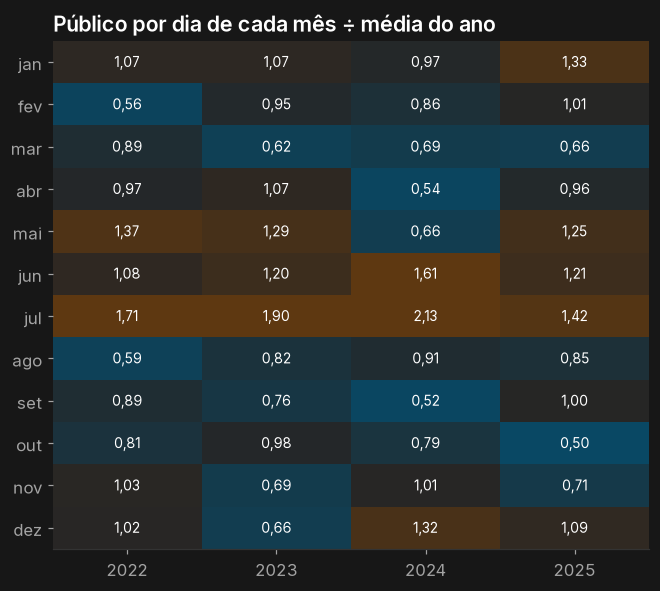

In [51]:
sazonal.index = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
mapa_calor(sazonal, "Público por dia de cada mês ÷ média do ano")

In [52]:
# em quantos dos 4 anos cada mês ficou acima da média do ano
(sazonal > 1).sum(axis=1).to_frame("n_anos_acima")

,n_anos_acima
jan,3
fev,1
mar,0
abr,1
mai,3
jun,4
jul,4
ago,0
set,1
out,0


Poucos padrões se repetem todo ano. Julho, nas férias escolares, ficou de 1,4 a 2,1 vezes a média do ano em 2022, 2023, 2024 e 2025. Junho também ficou acima da média nos quatro anos, só que menos (1,1 a 1,6). Março, agosto e outubro ficaram abaixo da média nos quatro.

Os outros meses sobem ou descem conforme os lançamentos de cada ano. Outubro, por exemplo, foi de 0,98 em 2023 para 0,50 em 2025. Fora junho e julho, quem manda no calendário é a data de estreia dos filmes grandes, e não o mês.

Por último, o horário. Reaproveito as sessões de 2025 por hora da pergunta 3, agora em faixas menores:

In [53]:
def faixa(hora):
    if hora < 12:
        return "1. até 12h"
    elif hora < 15:
        return "2. 12h–15h"
    elif hora < 18:
        return "3. 15h–18h"
    elif hora < 21:
        return "4. 18h–21h"
    return "5. 21h ou mais"

In [54]:
sessoes_2025["faixa"] = sessoes_2025["hora"].apply(faixa)
horas = sessoes_2025.groupby("faixa")[["n_sessoes", "publico"]].sum()
horas["pct_das_sessoes"] = horas["n_sessoes"] / horas["n_sessoes"].sum()
horas["pct_do_publico"] = horas["publico"] / horas["publico"].sum()
horas["publico_por_sessao"] = horas["publico"] / horas["n_sessoes"]
horas.style.format({"n_sessoes": br, "publico": mi, "pct_das_sessoes": pct, "pct_do_publico": pct, "publico_por_sessao": lambda v: br(v, 1)})

,n_sessoes,publico,pct_das_sessoes,pct_do_publico,publico_por_sessao
faixa,,,,,
1. até 12h,28.007,"0,5 mi","0,6%","0,4%","16,1"
2. 12h–15h,869.547,"13,6 mi","19,8%","11,9%","15,6"
3. 15h–18h,1.339.659,"33,9 mi","30,5%","29,7%","25,3"
4. 18h–21h,1.403.468,"48,1 mi","31,9%","42,1%","34,3"
5. 21h ou mais,753.539,"18,2 mi","17,1%","15,9%","24,2"


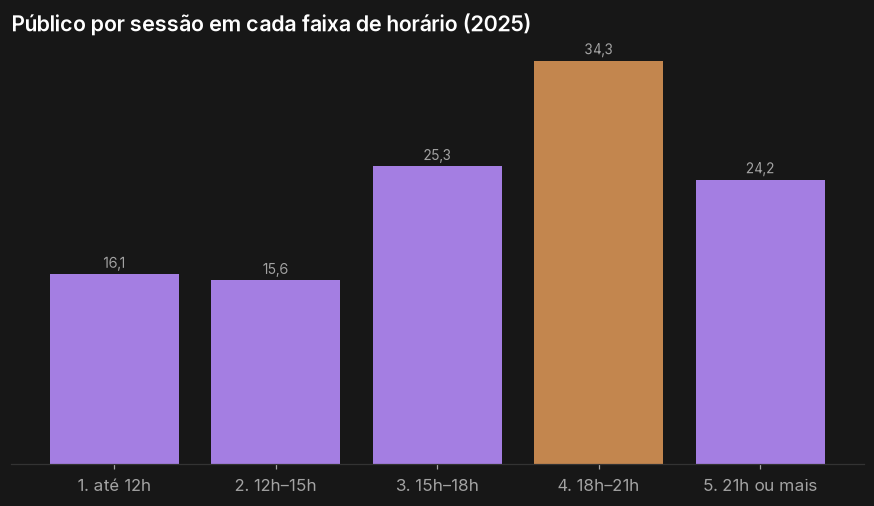

In [55]:
grafico_anos(horas["publico_por_sessao"], "Público por sessão em cada faixa de horário (2025)", lambda v: br(v, 1), destaques=["4. 18h–21h"])

A faixa das 18h às 21h é a que mais rende, com cerca de 34 pessoas por sessão. Depois das 21h ainda há bastante sessão, mas com menos gente em cada uma. As tardes têm muitas sessões e mais vazias, o mesmo sinal que apareceu na pergunta 3.

## 8. Dublado ou legendado?

Olho só os filmes estrangeiros, porque filme brasileiro não tem cópia dublada. A conta é quanto das sessões e do público foi em cópia dublada, por ano, pela fonte das exibidoras. Na base, a coluna `audio` só tem dois valores: `DUBLADO` e `ORIGINAL` (legendado).

In [56]:
dub_ano = consulta("""
    SELECT year(dia) AS ano, audio, count(*) AS n_sessoes, sum(publico) AS publico
    FROM e WHERE tipo = 'E' AND year(dia) <= 2025
    GROUP BY ano, audio
""")
sessoes = dub_ano.pivot(index="ano", columns="audio", values="n_sessoes")
publico = dub_ano.pivot(index="ano", columns="audio", values="publico")

In [57]:
dub = pd.DataFrame({"n_sessoes": sessoes.sum(axis=1)})
dub["pct_sessoes_dubladas"] = sessoes["DUBLADO"] / sessoes.sum(axis=1)
dub["pct_publico_dublado"] = publico["DUBLADO"] / publico.sum(axis=1)
dub.style.format({"n_sessoes": br, "pct_sessoes_dubladas": pct, "pct_publico_dublado": pct})

,n_sessoes,pct_sessoes_dubladas,pct_publico_dublado
ano,,,
2017,3.491.635,"72,2%","74,0%"
2018,3.630.305,"72,9%","74,9%"
2019,3.708.774,"76,2%","78,6%"
2020,1.169.699,"78,4%","80,9%"
2021,2.237.996,"81,4%","83,7%"
2022,3.384.487,"78,7%","81,6%"
2023,3.720.913,"82,0%","84,4%"
2024,3.625.988,"82,3%","86,1%"
2025,3.677.419,"82,9%","85,5%"


In [58]:
dub_reg = consulta("""
    SELECT regiao, audio, count(*) AS n_sessoes, sum(publico) AS publico
    FROM e JOIN regiao USING (uf)
    WHERE tipo = 'E' AND year(dia) = 2025
    GROUP BY regiao, audio
""")
sessoes_reg = dub_reg.pivot(index="regiao", columns="audio", values="n_sessoes")
publico_reg = dub_reg.pivot(index="regiao", columns="audio", values="publico")

In [59]:
dub_regiao = pd.DataFrame({"n_sessoes": sessoes_reg.sum(axis=1)})
dub_regiao["pct_sessoes_dubladas"] = sessoes_reg["DUBLADO"] / sessoes_reg.sum(axis=1)
dub_regiao["pct_publico_dublado"] = publico_reg["DUBLADO"] / publico_reg.sum(axis=1)
dub_regiao.sort_values("pct_publico_dublado").style.format({"n_sessoes": br, "pct_sessoes_dubladas": pct, "pct_publico_dublado": pct})

,n_sessoes,pct_sessoes_dubladas,pct_publico_dublado
regiao,,,
SUDESTE,1.950.736,"80,7%","84,0%"
CENTRO-OESTE,300.849,"83,5%","84,3%"
SUL,595.127,"83,5%","86,0%"
NORDESTE,602.357,"85,7%","87,8%"
NORTE,228.350,"91,7%","93,4%"


O dublado ganhou espaço. Em 2017 ele tinha 74% do público dos filmes estrangeiros e, em 2025, 86%. Não foi uma subida em linha reta (recuou um pouco em 2022 e de novo em 2025, depois dos 86,1% de 2024), mas a direção é clara: a cópia legendada virou nicho. O Norte é a região mais dublada (93% do público) e o Sudeste é a que mais mantém a legendada (84% dublado).

Uma coisa que me chamou atenção: a fatia do público nas dubladas é sempre um pouco maior que a fatia de sessões dubladas. Ou seja, em média, uma sessão dublada atrai mais gente que uma legendada.

## Conclusão

Voltando à pergunta do começo: o público não voltou. Em 2025, o cinema brasileiro teve 65% do público de 2019 (115 milhões de espectadores, contra 178 milhões). De janeiro a setembro de 2026 está em 77%, o primeiro avanço de verdade desde 2023, mas ainda abaixo de qualquer ano entre 2014 e 2019.

E não é falta de cinema. Em 2025, salas e sessões já eram as mesmas de 2019, e as exibições cresceram 17%. O que caiu foi o público por sessão, de 40 para 26 pessoas. Cada pergunta ajudou a explicar um pedaço disso:

1. Uns dois terços da perda estão nos 10 maiores filmes do ano. Há mais títulos em cartaz (759, contra 690) e menos filmes acima de 1 milhão de espectadores (27, contra 36). A melhora de 2026 veio de poucos títulos muito grandes.
2. O filme brasileiro voltou a ter cerca de 10% do público, mas leva menos da metade das pessoas de 2019. Depende de um sucesso por ano, e os sucessos de hoje são menores que os de antes.
3. A oferta voltou e até cresceu; a demanda, não. As sessões vazias quase triplicaram e se concentram à tarde.
4. São Paulo e Rio respondem por mais da metade da diferença. O Nordeste e Santa Catarina recuperaram mais, e o interior passou as capitais em público e ganhou salas.
5. As 5 maiores distribuidoras ficaram com 90% do público, com a Warner crescendo e a Disney e as nacionais perdendo espaço. Na exibição, as fatias mudaram pouco, e as salas independentes recuperaram melhor que as grandes redes.
6. A curva de um filme é a mesma de antes, com cerca de metade do público na primeira semana e 90% em uns 20 dias. Os lançamentos é que ficaram mais largos (770 salas no pico, contra 538).
7. Sábado é o dia mais forte, junho e julho são os únicos picos que se repetem todo ano, e a faixa das 18h às 21h é a mais cheia por sessão (cerca de 34 pessoas).
8. O dublado já leva 86% do público dos filmes estrangeiros, contra 74% em 2017.

### O que esses dados não mostram

- Não há preço nem receita, então não consigo separar o efeito do preço do ingresso do efeito de interesse do público.
- Não há a capacidade das salas, então o público por sessão é só uma aproximação da ocupação.
- Para comparar por habitante, eu precisaria da população do IBGE.
- A fonte das exibidoras só cobre o país todo a partir de 2017, e 2026 ainda está incompleto.
- Tudo aqui são associações. Nada disso prova causa.

### Próximos passos

O que eu faria em seguida: cruzar com a renda de bilheteria da ANCINE e com a população do IBGE, acompanhar o fechamento de 2026 e estudar a programação da tarde nas capitais do Sudeste, onde mais sobra lugar.